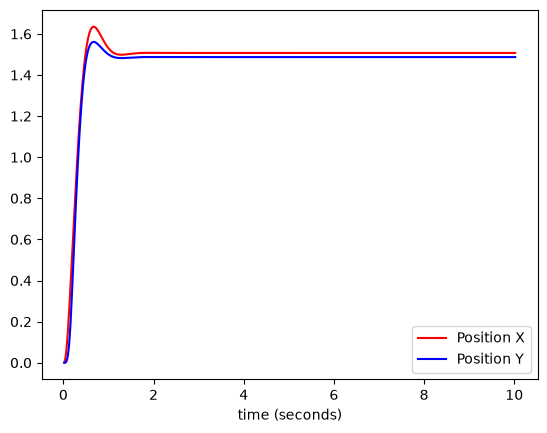

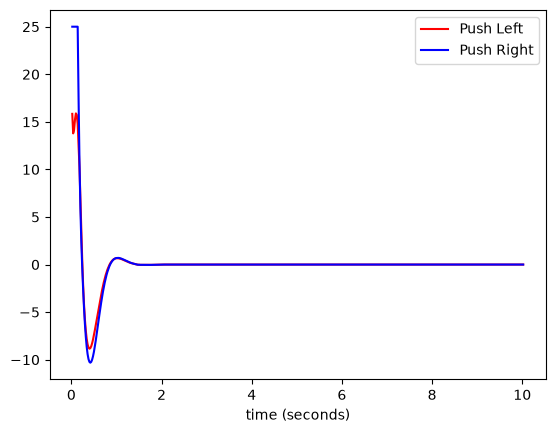

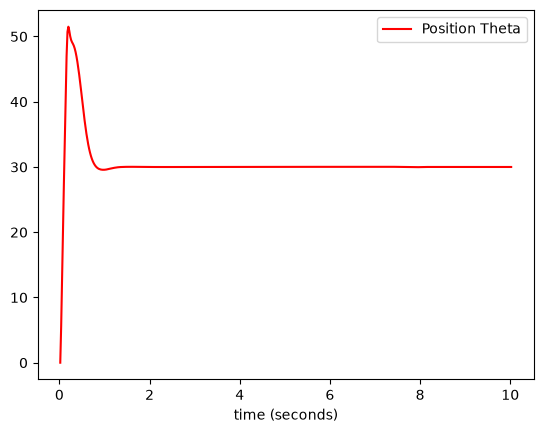

In [30]:
#
# to be tested with godot/cart-1d-no-physics
#

import numpy as np
import arslabrobotics as ar
import scipy.optimize as opt

class MPC_Cart_2D:

    def __init__(self):
        self.model_cart = ar.system.TwoWheelsCart2D(1.0, 0.15, 0.9, 0.9, 0.3)
        self.Q = np.array([10.0, 10.0, 1.0, 0.0, 0.0])  # Peso alto su errore posizione, basso su velocità
        self.R = np.array([0.01, 0.01])                    # Peso sull'azione di controllo (energia)
        self.N = 20
        self.target = np.array([0.0] * 5).T
        self.delta_t = 0.05
        # state vector x,y,theta,v,w
        self.initial_state = [0.0] * 5
        
        # max +-25 Newton
        self.max_force = 25.0

    def set_target(self, x, y, theta):
        self.target = np.array([ x, y, theta, 0, 0 ]).T

    def opt_fun(self, u_array):
        #print(u_array)
        self.model_cart.set_pose(*self.initial_state[:3])
        self.model_cart.v = self.initial_state[3]
        self.model_cart.w = self.initial_state[4]
        total_cost = 0
        for i in range(self.N):
            p = self.model_cart.get_pose()
            v = self.model_cart.get_speed()
            x = np.array([ p[0], p[1], p[2], v[0], v[1] ]).T
            
            error = self.target - x

            u = [u_array[i * 2], u_array[i * 2 + 1] ]

            cost = 0
            # quadratic cost function: J = x^T*Q*x + u^T*R*u
            for j in range(5):
                cost += self.Q[j] * (error[j]**2)
            
            cost += self.R[0] * (u[0]**2)            
            cost += self.R[1] * (u[1]**2)            
            
            total_cost += cost
            
            self.model_cart.evaluate(self.delta_t, u[0], u[1])
            
        return total_cost

    def optimize(self, delta_t, initial_u, pose, speed):
        self.initial_state = [pose[0], pose[1], pose[2], speed[0], speed[1]]
        self.delta_t = delta_t

        # Initial vector based on last command 
        u_init = []
        for _ in range(self.N):
            u_init.append(initial_u[0])
            u_init.append(initial_u[1])
        
        # Bounds of the input (saturation)
        bounds = opt.Bounds([-self.max_force] * (self.N * 2), [self.max_force] * (self.N * 2))
        
        result = opt.minimize(self.opt_fun, u_init, method='SLSQP', bounds=bounds)
        #print(result)
        return result.x
        
    

spd = ar.data.DataPlotter()
spd.set_x("time (seconds)")
spd.add_y("speed", "Speed")

pos = ar.data.DataPlotter()
pos.set_x("time (seconds)")
pos.add_y("pos_x", "Position X")
pos.add_y("pos_y", "Position Y")

angle = ar.data.DataPlotter()
angle.set_x("time (seconds)")
angle.add_y("theta", "Position Theta")

push = ar.data.DataPlotter()
push.set_x("time (seconds)")
push.add_y("push_left", "Push Left")
push.add_y("push_right", "Push Right")

cart = ar.system.TwoWheelsCart2D(1.0, 0.15, 0.5, 0.5, 0.3)

ctrl = MPC_Cart_2D()
ctrl.set_target(1.5, 1.5, np.radians(30))

godot_drive = False

if godot_drive:
    dds = ar.dds.DDS()
    dds.start()

#ctrl.optimize(0.1, 100, 0, 0)


t = ar.utils.Time(use_fake_time=not(godot_drive))
t.start()
force = [20, 20]
while t.get() < 10:

    t.sleep(0.02)
    t.elapsed()
    delta_t = 0.02

    force_array = ctrl.optimize(delta_t, force, cart.get_pose(), cart.get_speed())

    force = [force_array[0], force_array[1]]
    #print(force)
    
    cart.evaluate(delta_t, force[0], force[1])

    pose = cart.get_pose()
    speed = cart.get_speed()
    
    if godot_drive:
        dds.publish('X', pose[0], ar.dds.DDS_TYPE_FLOAT)
        dds.publish('Y', pose[1], ar.dds.DDS_TYPE_FLOAT)
        dds.publish('Theta', pose[2], ar.dds.DDS_TYPE_FLOAT)

    #spd.append_x(t.get())
    #spd.append_y("speed", v)
    
    pos.append_x(t.get())
    pos.append_y("pos_x", pose[0])
    pos.append_y("pos_y", pose[1])

    angle.append_x(t.get())
    angle.append_y("theta", np.degrees(pose[2]))
    
    push.append_x(t.get())
    push.append_y("push_left", force[0])
    push.append_y("push_right", force[1])
    
#spd.plot()
pos.plot()
push.plot()
angle.plot()
if godot_drive:
    dds.stop()
